In [1]:
import numpy as np
import matplotlib.pyplot as plt

SUHU_REF = np.array([25., 35., 40., 50.])

PPT = np.array([1, 2.5, 4, 6, 7.5, 10, 11, 13, 14.5, 16, 18, 20, 22, 23.5, 25.5]) # berurutan dari 1 gram garam sampai 15 gram garam

ADC_REF = np.array([
    [625, 629, 632, 638], # 1 gram garam
    [662, 666, 668, 674], # 2 gram garam
    [685, 687, 691, 696], # 3 gram garam
    [695, 697, 700, 704], # 4 gram garam
    [700, 703, 705, 709], # 5 gram garam
    [709, 710, 711, 713], # 6 gram garam
    [713, 714, 715, 716], # 7 gram garam
    [719, 720, 721, 722], # 8 gram garam 
    [722, 723, 724, 726], # 9 gram garam
    [725, 726, 727, 728], # 10 gram garam
    [726, 727, 728, 730], # 11 gram garam
    [728, 729, 730, 731], # 12 gram garam
    [730, 731, 732, 733], # 13 gram garam 
    [732, 733, 734, 735], # 14 gram garam
    [734, 735, 735, 736], # 15 gram garam
], dtype=float)

In [ ]:
def kurva_adc(suhu):
    suhu = np.clip(float(suhu), 25., 50.) # supaya suhu tidak keluar dari range referensi
    return np.array([np.interp(suhu, SUHU_REF, baris) for baris in ADC_REF])


def adc_ke_ppt(adc, suhu):
    adc = float(adc)
    kurva = kurva_adc(suhu)
    if adc < kurva[0]:
        return None   # belum dikalibrasi di bawah konsentrasi terendah
    if adc <= kurva[-1]:
        return float(np.interp(adc, kurva, PPT))
    
    # Kubik lokal pada kurva di suhu aktual, digeser agar kontinu pada batas atas.
    batas = kurva[-1]
    a, b, c, _ = np.polyfit(kurva - batas, PPT, 3)
    x = adc - batas
    return float(PPT[-1] + c*x + b*x*x + a*x*x*x)

ADC=695, suhu=25 C -> 6.000 ppt
ADC=695, suhu=45 C -> 4.353 ppt
ADC=704, suhu=53 C -> 6.000 ppt
ADC=704, suhu=55 C -> 6.000 ppt
ADC=700, suhu=37 C -> 6.482 ppt
ADC=740, suhu=41 C -> 30.345 ppt


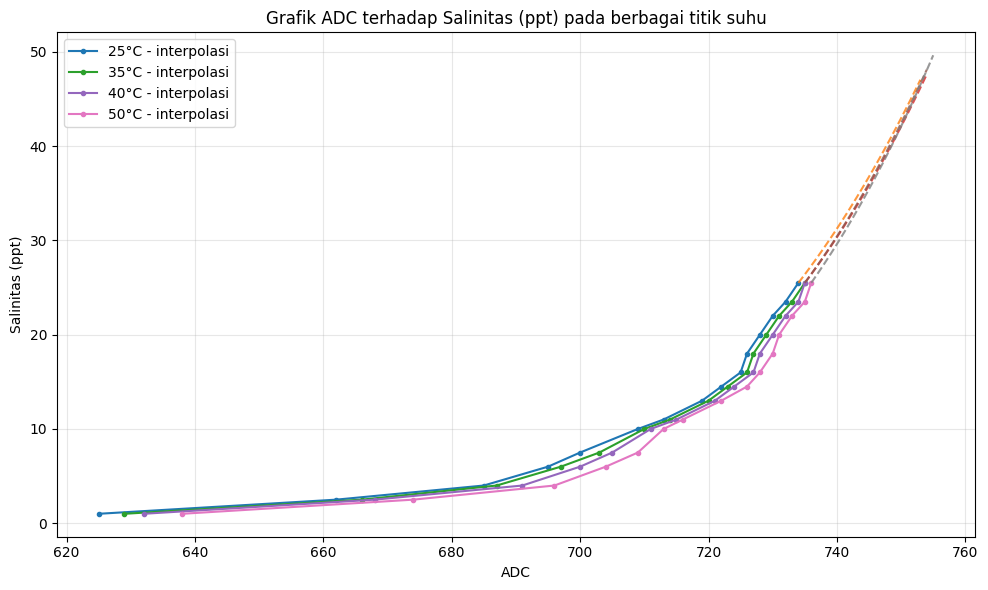

In [ ]:
# test
for a, t in [(695, 25), (695, 45), (704, 53), (704, 55), (700, 37), (740, 41)]:
    val = adc_ke_ppt(a, t)
    if (val is not None):
        print(f'ADC={a}, suhu={t} C -> {val:.3f} ppt')
    else:
        print(f'ADC={a}, suhu={t} C -> di bawah kalibrasi')


fig, ax = plt.subplots(figsize=(10,6))
for t in SUHU_REF:
    k = kurva_adc(t)
    ax.plot(k, PPT, marker='o', markersize=3, label=f'{t:.0f}°C - interpolasi')
    xx = np.linspace(k[-1], min(755, k[-1]+19), 80)
    yy = [adc_ke_ppt(x, t) for x in xx]
    ax.plot(xx, yy, linestyle='--', alpha=.8)
ax.set(xlabel='ADC', ylabel='Salinitas (ppt)', title='Grafik ADC terhadap Salinitas (ppt) pada berbagai titik suhu')
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
